# Customer Churn Prediction
**Author:** Manisha Debnath

**Goal:** Predict whether a telecom customer will leave (churn) using Machine Learning.

**Dataset:** Telco Customer Churn (Kaggle, IBM sample data)

**Tools:** Python, Pandas, Matplotlib, Seaborn, Scikit-learn, XGBoost

## Step 1: Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             confusion_matrix, f1_score, roc_auc_score, roc_curve)

sns.set_style("whitegrid")

## Step 2: Load the data
Upload `WA_Fn-UseC_-Telco-Customer-Churn.csv` to Colab (folder icon on the left -> upload) before running this cell.

In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Rows, Columns:", df.shape)
df.head()

Rows, Columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## Step 3: Clean the data
`TotalCharges` is stored as text and has a few blank values, so we convert it to numbers and fill the blanks with the median. The `customerID` column is just an ID, so we drop it.

In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing values before:\n", df.isnull().sum()[df.isnull().sum() > 0])

df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())
df = df.drop("customerID", axis=1)

print("\nMissing values after:", df.isnull().sum().sum())

Missing values before:
 TotalCharges    11
dtype: int64

Missing values after: 0


## Step 4: Exploratory Data Analysis (EDA)
We look at the data with charts to understand why customers leave.

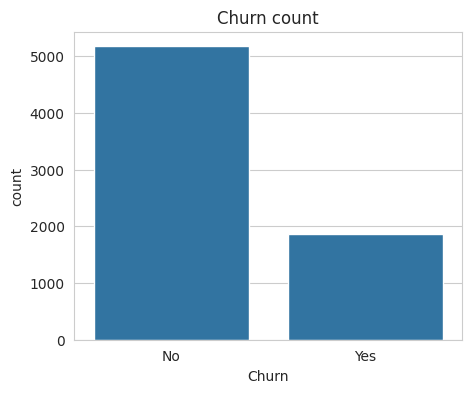

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [5]:
# How many customers churned?
plt.figure(figsize=(5,4))
sns.countplot(x="Churn", data=df)
plt.title("Churn count")
plt.show()
print(df["Churn"].value_counts(normalize=True) * 100)

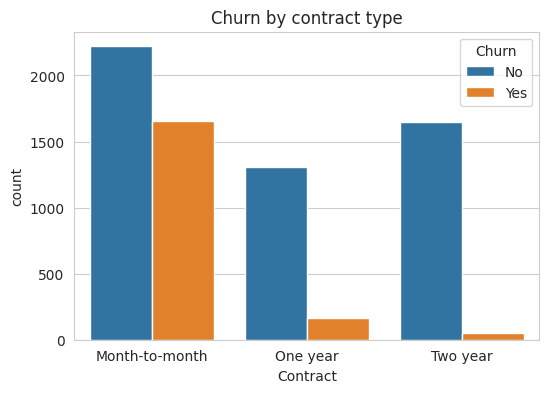

In [6]:
# Churn by contract type
plt.figure(figsize=(6,4))
sns.countplot(x="Contract", hue="Churn", data=df)
plt.title("Churn by contract type")
plt.show()

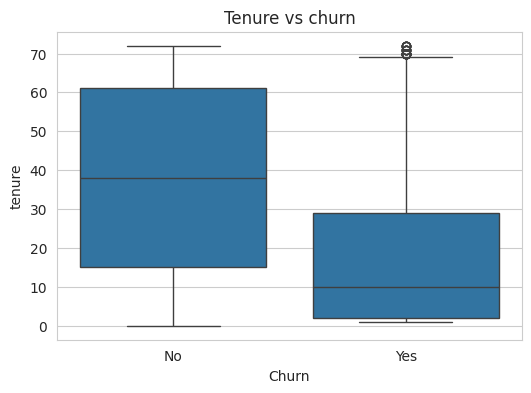

In [7]:
# Tenure (months with company) vs churn
plt.figure(figsize=(6,4))
sns.boxplot(x="Churn", y="tenure", data=df)
plt.title("Tenure vs churn")
plt.show()

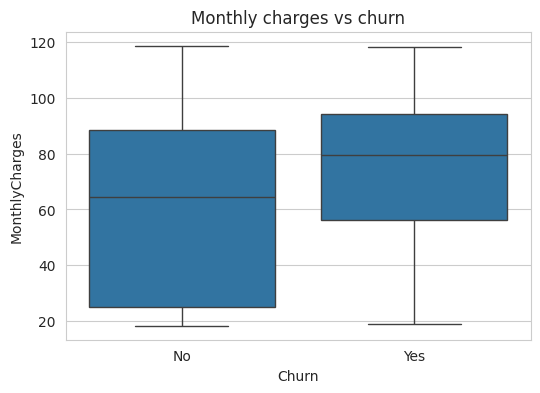

In [8]:
# Monthly charges vs churn
plt.figure(figsize=(6,4))
sns.boxplot(x="Churn", y="MonthlyCharges", data=df)
plt.title("Monthly charges vs churn")
plt.show()

**What I observed (check your own charts and edit this):**
- Customers on month-to-month contracts tend to churn more than those on one- or two-year contracts.
- Customers who churn usually have a shorter tenure (they are newer customers).
- Customers who churn tend to have higher monthly charges.

## Step 5: Prepare the data for machine learning
Models only understand numbers, so we convert text columns to numbers (one-hot encoding) and turn `Churn` into 0/1.

In [9]:
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

df_encoded = pd.get_dummies(df, drop_first=True)

X = df_encoded.drop("Churn", axis=1)
y = df_encoded["Churn"]
print("Features:", X.shape, " Target:", y.shape)

Features: (7043, 30)  Target: (7043,)


In [10]:
# Split: 80% for training, 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Scale the numbers (needed for Logistic Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Step 6: Handle class imbalance
Only about 1 in 4 customers churns, so a model can get high accuracy by mostly predicting "No churn" and still miss the customers we care about. We fix this by giving the minority class (churners) more weight during training.

In [11]:
print(y_train.value_counts())
ratio = (y_train == 0).sum() / (y_train == 1).sum()
print("\nNo-churn : churn ratio =", round(ratio, 2), ": 1")

Churn
0    4139
1    1495
Name: count, dtype: int64

No-churn : churn ratio = 2.77 : 1


## Step 7: Train the models
We train 5 models: Logistic Regression and Random Forest **without** balancing (to see the problem), then **with** balancing, plus XGBoost.

In [12]:
models = {}

# 1. Without balancing (baseline)
models["Logistic Reg (no balance)"] = LogisticRegression(max_iter=1000)
models["Random Forest (no balance)"] = RandomForestClassifier(n_estimators=200, random_state=42)

# 2. With class balancing
models["Logistic Reg (balanced)"] = LogisticRegression(max_iter=1000, class_weight="balanced")
models["Random Forest (balanced)"] = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)

# 3. XGBoost (scale_pos_weight handles imbalance)
from xgboost import XGBClassifier
models["XGBoost (balanced)"] = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1,
                                             scale_pos_weight=ratio, eval_metric="logloss", random_state=42)

for name, m in models.items():
    if "Logistic" in name:
        m.fit(X_train_scaled, y_train)   # Logistic Regression needs scaled data
    else:
        m.fit(X_train, y_train)
    print("Trained:", name)

Trained: Logistic Reg (no balance)
Trained: Random Forest (no balance)
Trained: Logistic Reg (balanced)
Trained: Random Forest (balanced)
Trained: XGBoost (balanced)


## Step 8: Evaluate and compare the models
We compare accuracy, precision, recall, F1-score and ROC-AUC. **Recall** is very important here: it shows how many of the customers who really churned we managed to catch.

In [13]:
results = {}
probs = {}

for name, m in models.items():
    X_t = X_test_scaled if "Logistic" in name else X_test
    pred = m.predict(X_t)
    prob = m.predict_proba(X_t)[:, 1]
    probs[name] = prob
    results[name] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
    }

results_df = pd.DataFrame(results).T.round(3)
results_df

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Logistic Reg (no balance),0.807,0.658,0.567,0.609,0.842
Random Forest (no balance),0.790,0.634,0.495,0.556,0.826
Logistic Reg (balanced),0.739,0.505,0.781,0.613,0.841
Random Forest (balanced),0.789,0.631,0.497,0.556,0.825
XGBoost (balanced),0.754,0.525,0.781,0.628,0.836


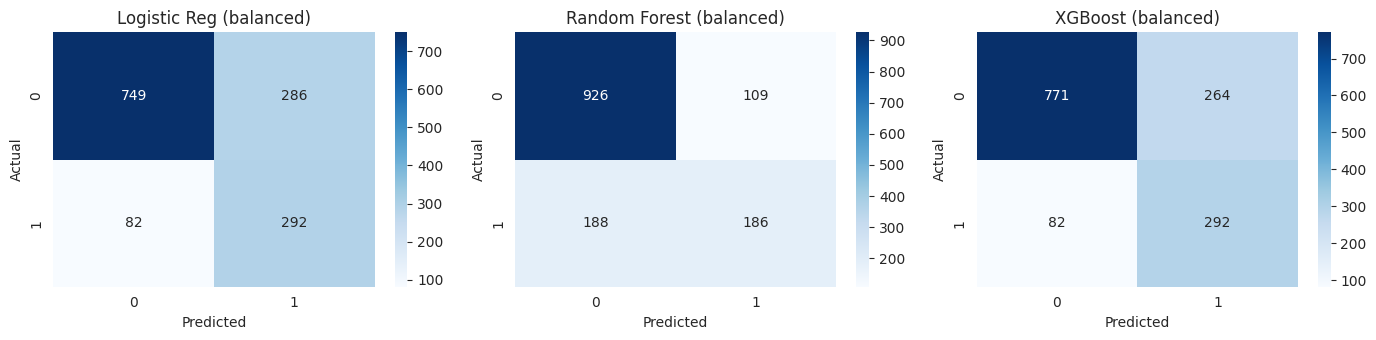

In [14]:
# Confusion matrices of the three balanced models
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, name in zip(axes, ["Logistic Reg (balanced)", "Random Forest (balanced)", "XGBoost (balanced)"]):
    X_t = X_test_scaled if "Logistic" in name else X_test
    cm = confusion_matrix(y_test, models[name].predict(X_t))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax)
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

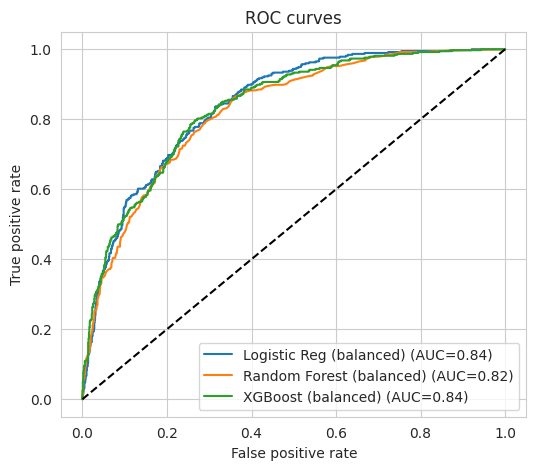

In [15]:
# ROC curves
plt.figure(figsize=(6, 5))
for name in ["Logistic Reg (balanced)", "Random Forest (balanced)", "XGBoost (balanced)"]:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    plt.plot(fpr, tpr, label=name + " (AUC=" + str(round(results_df.loc[name, "ROC-AUC"], 2)) + ")")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves"); plt.legend()
plt.show()

**What I observed (write this after you see your own table):**
- Balancing the classes raised recall: the models catch more of the customers who really churn, at the cost of some precision.
- Compare all models on F1-score and ROC-AUC, not only accuracy.

## Step 9: Which factors are associated with churn?

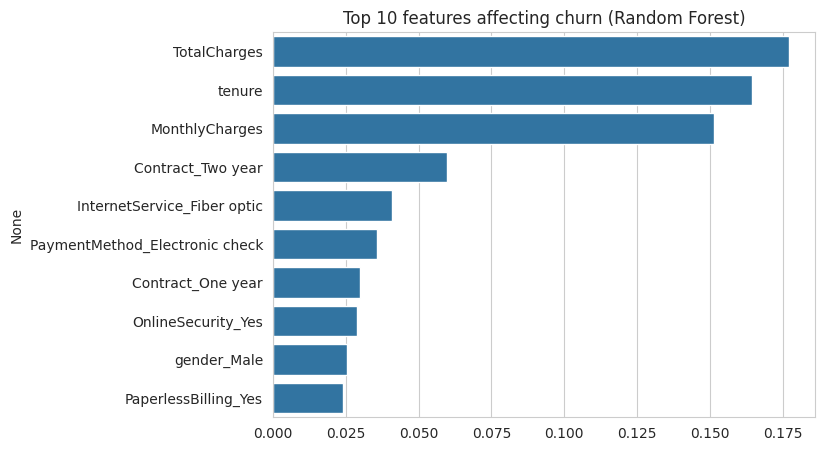

In [16]:
# Feature importance from Random Forest
importances = pd.Series(models["Random Forest (balanced)"].feature_importances_, index=X.columns)
top10 = importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(7, 5))
sns.barplot(x=top10.values, y=top10.index)
plt.title("Top 10 features affecting churn (Random Forest)")
plt.show()

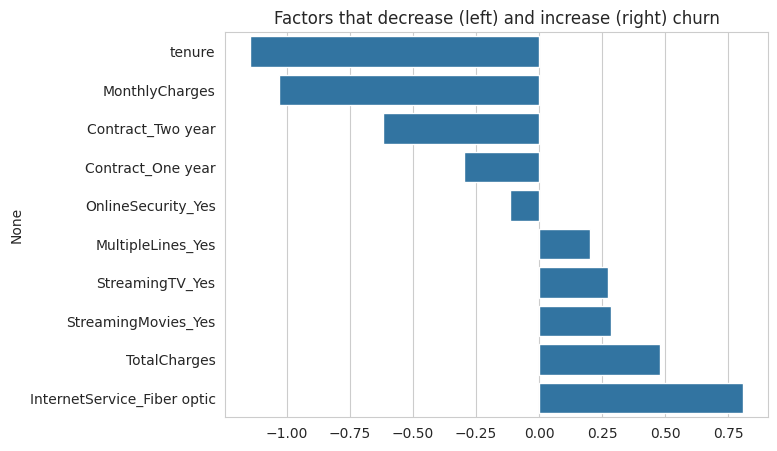

In [17]:
# Direction of effect from Logistic Regression
# Positive = increases chance of churn, Negative = decreases it
coef = pd.Series(models["Logistic Reg (balanced)"].coef_[0], index=X.columns).sort_values()
top_coef = pd.concat([coef.head(5), coef.tail(5)])

plt.figure(figsize=(7, 5))
sns.barplot(x=top_coef.values, y=top_coef.index)
plt.title("Factors that decrease (left) and increase (right) churn")
plt.show()

## Step 10: How a company can use these predictions to retain customers
The model gives each customer a churn probability. We split customers into risk groups so the retention team can focus on the right people.

In [18]:
# Use the model with the best ROC-AUC
best_name = results_df["ROC-AUC"].idxmax()
print("Best model by ROC-AUC:", best_name)

risk = X_test.copy()
risk["churn_probability"] = probs[best_name]
risk["risk_level"] = pd.cut(risk["churn_probability"], bins=[0, 0.4, 0.7, 1.0],
                            labels=["Low", "Medium", "High"], include_lowest=True)
risk["actual_churn"] = y_test.values

print(risk["risk_level"].value_counts())
print("\nActual churn rate in each risk group:")
print(risk.groupby("risk_level", observed=True)["actual_churn"].mean().round(2))

Best model by ROC-AUC: Logistic Reg (no balance)
risk_level
Low       968
Medium    352
High       89
Name: count, dtype: int64

Actual churn rate in each risk group:
risk_level
Low       0.13
Medium    0.53
High      0.73
Name: actual_churn, dtype: float64


In [19]:
# Top 10 customers the company should call first
risk.sort_values("churn_probability", ascending=False)[["tenure", "MonthlyCharges", "churn_probability"]].head(10)

,tenure,MonthlyCharges,churn_probability
3380,1,95.10,0.854954
6866,1,95.45,0.831877
2631,7,99.25,0.830124
6365,7,101.95,0.819310
3346,2,84.05,0.818969
4585,1,85.05,0.818527
2797,3,100.95,0.816899
6894,3,105.90,0.815362
3727,3,96.60,0.815357
935,4,83.25,0.814812


**How the company can use this:**
1. **High-risk customers:** call them with a personal offer, such as a discount or a free upgrade.
2. **Medium-risk customers:** send reminders about benefits, or offer a switch to a longer contract.
3. **Low-risk customers:** no action needed, so retention money is not wasted.
4. **Fix root causes:** if month-to-month contracts and high monthly charges drive churn, offer new customers a discounted one-year plan.

The model does not stop churn by itself. It tells the company *who* to focus on, and it is cheaper to retain a customer than to win a new one.

## Conclusion


- Best model by ROC-AUC: Logistic Regression (0.842). Best F1-score among the balanced models: XGBoost (0.628, recall 0.781).
- Balancing the classes raised Logistic Regression recall from 0.567 to 0.781, so it catches many more churners.
- Key factors behind churn: short tenure, month-to-month contracts, Fiber optic internet, and higher total and monthly charges.
- Customers the model marks as high risk churned 73% of the time versus 13% for low risk, so a retention team can focus on them first.

**Limitations / future work:** tune hyperparameters, try SMOTE, build a pipeline, and deploy the model with Streamlit.